# 06 · Seleksi Fitur & Tuning LightGBM

Notebook 05 menunjukkan bahwa menambah fitur sejenis tidak lagi menaikkan KS. Notebook ini menguji dua pengungkit lain yang saling memengaruhi:

1. **Seleksi fitur:** membuang fitur dengan importance terendah. Hipotesisnya, puluhan fitur nyaris tanpa sinyal menambah noise ke setiap split.
2. **Regularisasi / tuning:** membuat setiap pohon lebih "sederhana" dan lebih tahan noise.

Kedua pengungkit ini bisa **saling menggantikan**. Model yang hanya melihat 30–40% kolom per pohon (`colsample_bytree` kecil) dan butuh banyak data per daun (`min_child_samples` besar) sudah otomatis lebih jarang memakai fitur noise. Karena itu keduanya diuji dalam satu notebook, termasuk kombinasinya.

| Parameter | Baseline | Arti | Arah regularisasi |
|---|---|---|---|
| `num_leaves` | 31 | jumlah daun maksimum per pohon (kompleksitas interaksi) | lebih kecil (7) |
| `min_child_samples` | 100 | minimum baris per daun | lebih besar (300–1000) |
| `colsample_bytree` | 0,8 | porsi kolom yang boleh dipakai satu pohon | lebih kecil (0,3–0,4) |
| `reg_lambda` | 1 | penalti L2 untuk nilai daun | lebih besar (10–30) |
| `extra_trees` | False | ambang split dipilih acak (lebih sedikit *overfitting* pada ambang) | True |

**Protokol** (sama dengan notebook 05):

- **Tahap A (3 seed):** 9 konfigurasi dibandingkan berpasangan dengan baseline untuk membuat peringkat.
- **Tahap B (5 seed):** 2 teratas diuji ulang dan diputuskan dengan aturan yang sama:
  - **jelas:** Δ ≥ 0,005, semua seed naik
  - **tipis:** Δ ≥ 0,002, semua seed naik
  - **tidak:** selain itu
- Noise placebo dari notebook 05 (±0,0015–0,002) menjadi acuan ambang "tipis".

> Waktu jalan ±40 menit di laptop Anda. `QUICK = True` hanya menguji 5 konfigurasi di tahap A (±25 menit).

In [1]:
import gc
import json
import time
import numpy as np
import polars as pl
import matplotlib.pyplot as plt
import eda_utils as E
import features as F
import modeling as M

E.setup_style()
pl.Config.set_tbl_rows(60)
pl.Config.set_tbl_hide_dataframe_shape(True)
pl.Config.set_fmt_str_lengths(70)

meta = json.loads((M.FEAT_DIR / "features_v1.json").read_text())
train = pl.read_parquet(M.FEAT_DIR / "train_v1.parquet")
test = pl.read_parquet(M.FEAT_DIR / "test_v1.parquet")
FEAT, CATS = meta["features"], meta["categorical"]
y = train["target"].to_numpy()
SEG = train["segment"].to_numpy()
SEEDS_A = (42, 7, 2024)
SEEDS_B = (42, 7, 2024, 11, 99)
QUICK = False
print(f"v1: {len(FEAT)} fitur | e-commerce: {meta['ecommerce_source']}")

v1: 191 fitur | e-commerce: ecommerce_transactions.csv


## 1. Baseline (5 seed) & peringkat importance

Baseline = parameter notebook 04 pada 191 fitur v1. Importance (gain) dijumlahkan dari 25 model (5 seed × 5 fold) dan dipakai untuk memilih fitur pada konfigurasi "top-K".

**Catatan bias seleksi:** importance dihitung dari model yang dilatih pada data yang sama dengan yang dipakai untuk menilai seleksi. Ini sedikit menguntungkan konfigurasi top-K. Hanya sedikit, karena setiap model fold tidak pernah melihat fold validasinya dan hanya beberapa nilai K yang dicoba. Aturan "semua seed naik" menahan sisanya.

In [2]:
RUNS, CMP = {}, {}
RUNS["baseline"] = base = M.train_lgb_cv(train, test, FEAT, CATS, seeds=SEEDS_B)
IMP = base["importance"]
for k in (40, 80, 120):
    print(f"top-{k} fitur memegang {IMP['gain_pct'].head(k).sum():.1f}% total gain")
TOP = {k: IMP["feature"].head(k).to_list() for k in (50, 80, 120)}

seed 42: KS OOF 0.5178  (54s)
seed 7: KS OOF 0.5186  (118s)
seed 2024: KS OOF 0.5176  (175s)
seed 11: KS OOF 0.5162  (235s)
seed 99: KS OOF 0.5176  (295s)
KS OOF rata-rata 5 seed: 0.5194 | per seed: 0.5178, 0.5186, 0.5176, 0.5162, 0.5176
top-40 fitur memegang 75.2% total gain
top-80 fitur memegang 87.4% total gain
top-120 fitur memegang 95.3% total gain


## 2. Tahap A — peringkat konfigurasi (3 seed)

Konfigurasi disusun dari eksplorasi awal saya (data sampling): satu pengungkit sekaligus dulu, lalu kombinasinya.

In [3]:
RS = dict(num_leaves=7, min_child_samples=300, colsample_bytree=0.4, reg_lambda=10)   # "regularisasi kuat"
CONFIGS = {
    # nama: (fitur, parameter, deskripsi)
    "seleksi top-80":         (TOP[80], {}, "parameter baseline, hanya 80 fitur teratas"),
    "seleksi top-120":        (TOP[120], {}, "parameter baseline, 120 fitur teratas"),
    "min_child 300":          (FEAT, dict(min_child_samples=300), "satu pengungkit: daun lebih besar"),
    "colsample 0.4":          (FEAT, dict(colsample_bytree=0.4), "satu pengungkit: kolom per pohon lebih sedikit"),
    "regularisasi kuat":      (FEAT, RS, "daun 7, min_child 300, colsample 0,4, lambda 10"),
    "regularisasi lebih kuat": (FEAT, dict(num_leaves=7, min_child_samples=600, colsample_bytree=0.3, reg_lambda=10),
                                "daun 7, min_child 600, colsample 0,3, lambda 10"),
    "regularisasi sangat kuat": (FEAT, dict(num_leaves=7, min_child_samples=1000, colsample_bytree=0.3, reg_lambda=30),
                                 "daun 7, min_child 1000, colsample 0,3, lambda 30"),
    "reg. kuat + extra_trees": (FEAT, {**RS, "extra_trees": True}, "regularisasi kuat + ambang split acak"),
    "reg. kuat + top-80":      (TOP[80], RS, "kedua pengungkit sekaligus"),
}
if QUICK:
    CONFIGS = {k: CONFIGS[k] for k in ["seleksi top-80", "regularisasi kuat", "regularisasi lebih kuat",
                                       "reg. kuat + extra_trees", "reg. kuat + top-80"]}

for name, (feats, prm, _) in CONFIGS.items():
    t = time.time()
    RUNS[name] = M.train_lgb_cv(train, test, feats, [c for c in CATS if c in feats], seeds=SEEDS_A, params=prm, verbose=False)
    CMP[name] = M.compare_runs(base, RUNS[name], y, SEG)
    print(f"{name:26s} Δ per seed {[round(d, 4) for d in CMP[name]['per_seed']['delta']]} "
          f"| rata-rata {CMP[name]['delta_seed_mean']:+.4f} | iterasi median {int(np.median(RUNS[name]['best_iters']))} "
          f"| {time.time() - t:.0f} detik")
    gc.collect()

seleksi top-80             Δ per seed [-0.0029, -0.0014, -0.0022] | rata-rata -0.0022 | iterasi median 292 | 76 detik
seleksi top-120            Δ per seed [-0.0011, -0.0005, 0.0004] | rata-rata -0.0004 | iterasi median 288 | 110 detik
min_child 300              Δ per seed [0.0006, 0.0013, -0.0001] | rata-rata +0.0006 | iterasi median 293 | 165 detik
colsample 0.4              Δ per seed [0.0021, 0.0013, 0.0014] | rata-rata +0.0016 | iterasi median 361 | 99 detik
regularisasi kuat          Δ per seed [0.0011, 0.0013, 0.0023] | rata-rata +0.0016 | iterasi median 818 | 124 detik
regularisasi lebih kuat    Δ per seed [0.0038, 0.0011, 0.0049] | rata-rata +0.0033 | iterasi median 881 | 113 detik
regularisasi sangat kuat   Δ per seed [0.0023, 0.0021, 0.0037] | rata-rata +0.0027 | iterasi median 865 | 113 detik
reg. kuat + extra_trees    Δ per seed [0.004, 0.0002, 0.0041] | rata-rata +0.0028 | iterasi median 1167 | 172 detik
reg. kuat + top-80         Δ per seed [0.0022, 0.0012, 0.0018] | rat

In [4]:
def row(name):
    c, r = CMP[name], RUNS[name]
    out = dict(konfigurasi=name, n_fitur=len(r["features"]), delta_oof=c["delta_oof"])
    out.update({f"d_s{s}": d for s, d in zip(c["per_seed"]["seed"], c["per_seed"]["delta"])})
    out.update(delta_rata2=c["delta_seed_mean"], seed_naik=f"{c['n_seed_positive']}/{c['per_seed'].height}",
               iterasi=int(np.median(r["best_iters"])))
    return out

stage_a = pl.DataFrame([row(n) for n in CONFIGS]).sort("delta_rata2", descending=True)
stage_a.with_columns(pl.col(pl.Float64).round(4))

konfigurasi,n_fitur,delta_oof,d_s42,d_s7,d_s2024,delta_rata2,seed_naik,iterasi
str,i64,f64,f64,f64,f64,f64,str,i64
"""regularisasi lebih kuat""",191,0.0032,0.0038,0.0011,0.0049,0.0033,"""3/3""",881
"""reg. kuat + extra_trees""",191,0.0043,0.004,0.0002,0.0041,0.0028,"""3/3""",1167
"""regularisasi sangat kuat""",191,0.0026,0.0023,0.0021,0.0037,0.0027,"""3/3""",865
"""reg. kuat + top-80""",80,0.0011,0.0022,0.0012,0.0018,0.0017,"""3/3""",773
"""colsample 0.4""",191,0.0021,0.0021,0.0013,0.0014,0.0016,"""3/3""",361
"""regularisasi kuat""",191,0.0012,0.0011,0.0013,0.0023,0.0016,"""3/3""",818
"""min_child 300""",191,0.0004,0.0006,0.0013,-0.0001,0.0006,"""2/3""",293
"""seleksi top-120""",120,0.0002,-0.0011,-0.0005,0.0004,-0.0004,"""1/3""",288
"""seleksi top-80""",80,-0.002,-0.0029,-0.0014,-0.0022,-0.0022,"""0/3""",292


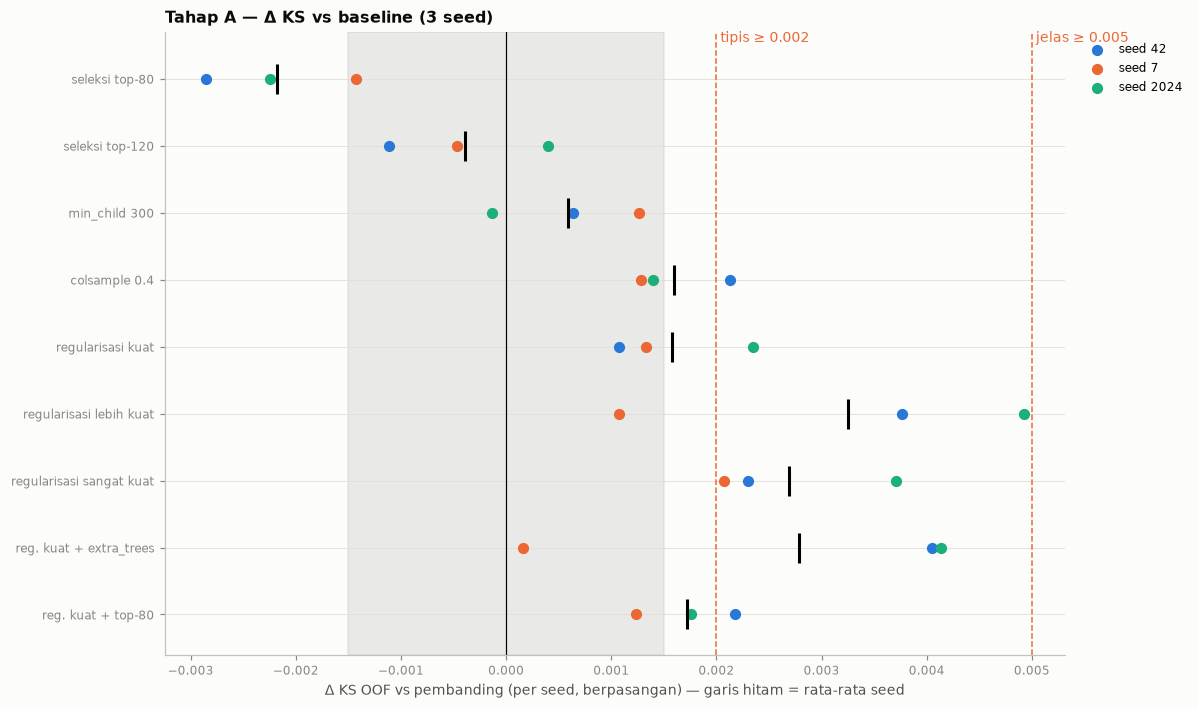

In [5]:
M.plot_paired_deltas(CMP, list(CONFIGS), noise=0.0015, title="Tahap A — Δ KS vs baseline (3 seed)")

**Cara membaca:**

- **Baris "satu pengungkit"** (`min_child 300`, `colsample 0.4`, `seleksi top-K`) menunjukkan seberapa besar setiap pengungkit membantu sendirian.
- **Baris "regularisasi"** menunjukkan apakah gabungannya saling menambah.
- **Baris "reg. kuat + top-80"** menjawab apakah seleksi fitur masih berguna setelah model diregularisasi. Kalau Δ-nya **lebih kecil** dari "regularisasi kuat" saja, kedua pengungkit saling menggantikan: regularisasi sudah membuat model mengabaikan fitur noise, sehingga membuang fitur justru menghilangkan sedikit informasi yang masih berguna.
- Kolom `iterasi`: model yang lebih sederhana butuh lebih banyak pohon (daun 7 → ±800–1.000 pohon vs ±300 di baseline). Waktu latih tetap mirip karena setiap pohon lebih kecil.

## 3. Tahap B — dua teratas dengan 5 seed

Perhatikan dua angka yang berbeda di output:
- **Δ per seed:** rata-rata selisih KS model tunggal per seed.
- **Δ OOF gabungan:** selisih setelah OOF 5 seed dirata-rata.

Biasanya Δ OOF gabungan lebih kecil. Model teregularisasi lebih stabil antar seed, sehingga baseline yang lebih "goyang" mendapat manfaat lebih besar dari perataan seed. Prediksi test adalah rata-rata 25 model, jadi Δ OOF gabungan adalah perkiraan yang lebih realistis untuk submission.

In [6]:
FINALISTS = stage_a["konfigurasi"].head(2).to_list()
for name in FINALISTS:
    feats, prm, _ = CONFIGS[name]
    t = time.time()
    key = name + " (5 seed)"
    RUNS[key] = M.train_lgb_cv(train, test, feats, [c for c in CATS if c in feats], seeds=SEEDS_B, params=prm, verbose=False)
    CMP[key] = M.compare_runs(base, RUNS[key], y, SEG)
    print(f"{key:36s} KS OOF {RUNS[key]['ks_oof']:.4f} (baseline {base['ks_oof']:.4f}) "
          f"| Δ per seed {[round(d, 4) for d in CMP[key]['per_seed']['delta']]} "
          f"| rata-rata {CMP[key]['delta_seed_mean']:+.4f} | keputusan: {M.verdict(CMP[key], noise=0.0015)} "
          f"| {time.time() - t:.0f} detik")

regularisasi lebih kuat (5 seed)     KS OOF 0.5219 (baseline 0.5194) | Δ per seed [0.0038, 0.0011, 0.0049, 0.002, -0.0004] | rata-rata +0.0023 | keputusan: tidak | 204 detik
reg. kuat + extra_trees (5 seed)     KS OOF 0.5227 (baseline 0.5194) | Δ per seed [0.004, 0.0002, 0.0041, 0.0037, 0.0014] | rata-rata +0.0027 | keputusan: tipis | 291 detik


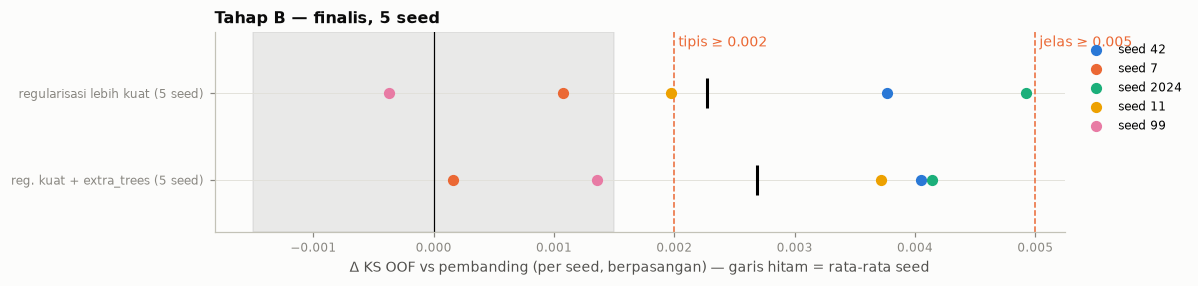

konfigurasi,n_fitur,delta_oof,d_s42,d_s7,d_s2024,d_s11,d_s99,delta_rata2,seed_naik,iterasi,keputusan
str,i64,f64,f64,f64,f64,f64,f64,f64,str,i64,str
"""regularisasi lebih kuat (5 seed)""",191,0.0025,0.0038,0.0011,0.0049,0.002,-0.0004,0.0023,"""4/5""",846,"""tidak"""
"""reg. kuat + extra_trees (5 seed)""",191,0.0032,0.004,0.0002,0.0041,0.0037,0.0014,0.0027,"""5/5""",1167,"""tipis"""


In [7]:
B_KEYS = [n + " (5 seed)" for n in FINALISTS]
M.plot_paired_deltas(CMP, B_KEYS, noise=0.0015, title="Tahap B — finalis, 5 seed")
stage_b = pl.DataFrame([{**row(k), "keputusan": M.verdict(CMP[k], noise=0.0015)} for k in B_KEYS])
stage_b.with_columns(pl.col(pl.Float64).round(4))

In [8]:
passing = [k for k in B_KEYS if M.verdict(CMP[k], noise=0.0015) in ("jelas", "tipis")]
BEST = max(passing, key=lambda k: CMP[k]["delta_seed_mean"]) if passing else None
if BEST:
    BEST_NAME = BEST.replace(" (5 seed)", "")
    BEST_FEATS, BEST_PARAMS, BEST_DESC = CONFIGS[BEST_NAME]
    print(f"Dipilih: {BEST_NAME} — {BEST_DESC}")
    print(f"KS OOF 5 seed {RUNS[BEST]['ks_oof']:.4f} vs baseline {base['ks_oof']:.4f} (Δ {CMP[BEST]['delta_oof']:+.4f})")
    display(CMP[BEST]["per_segment"].with_columns(pl.col(pl.Float64).round(4)))
else:
    print("Tidak ada finalis yang lolos → parameter baseline tetap dipakai.")

Dipilih: reg. kuat + extra_trees — regularisasi kuat + ambang split acak
KS OOF 5 seed 0.5227 vs baseline 0.5194 (Δ +0.0032)


segment,n,ks_base,ks_baru,delta
str,i64,f64,f64,f64
"""SEMUA""",70000,0.5194,0.5227,0.0032
"""A_no_history""",21000,0.4947,0.4952,0.0006
"""B_apps_no_installments""",2688,0.5158,0.5308,0.015
"""C_has_installments""",46312,0.5307,0.5353,0.0046


## 4. Pemeriksaan model terpilih

1. **Optimisme early stopping:** latih ulang seed 42 dengan jumlah pohon tetap (median iterasi terbaik). Model yang lebih sederhana memakai lebih banyak pohon, jadi optimisme ini perlu dicek ulang.
2. **Ke mana gain berpindah:** dengan kolom per pohon lebih sedikit, fitur terkuat tidak selalu tersedia di setiap pohon. Gain-nya lalu berpindah ke fitur "saudara" yang membawa informasi serupa.

In [9]:
if BEST:
    n_fixed = int(np.median(RUNS[BEST]["best_iters"]))
    fx = M.train_lgb_cv(train, test, BEST_FEATS, [c for c in CATS if c in BEST_FEATS], seeds=(42,), early_stopping=None,
                        params={**BEST_PARAMS, "n_estimators": n_fixed}, verbose=False)
    es42 = RUNS[BEST]["ks_by_seed"][42]
    print(f"Seed 42: early stopping {es42:.4f} | {n_fixed} pohon tetap {fx['ks_oof']:.4f} | optimisme {es42 - fx['ks_oof']:+.4f}")
    print(f"Seed 42 baseline (early stopping): {base['ks_by_seed'][42]:.4f} → Δ jujur {fx['ks_oof'] - base['ks_by_seed'][42]:+.4f}")

Seed 42: early stopping 0.5219 | 1167 pohon tetap 0.5204 | optimisme +0.0015
Seed 42 baseline (early stopping): 0.5178 → Δ jujur +0.0026


In [10]:
if BEST:
    def by_source(imp):
        return (imp.with_columns(sumber=pl.Series([F.feature_group(c) for c in imp["feature"]]))
                   .group_by("sumber").agg(gain_pct=pl.col("gain_pct").sum()))
    src = (by_source(base["importance"]).rename({"gain_pct": "baseline"})
           .join(by_source(RUNS[BEST]["importance"]).rename({"gain_pct": "terpilih"}), on="sumber", how="left")
           .sort("baseline", descending=True))
    top = (base["importance"].head(10).rename({"gain_pct": "gain_baseline"})
           .join(RUNS[BEST]["importance"].rename({"gain_pct": "gain_terpilih"}), on="feature", how="left"))
    for c in ("baseline", "terpilih"):
        src = src.with_columns(pl.col(c).round(1))
    display(src)
    print("Gain 10 fitur teratas baseline — sebelum vs sesudah:")
    display(top.with_columns(pl.col(pl.Float64).round(2)))
    print(f"Gain 10 fitur teratas: baseline {base['importance']['gain_pct'].head(10).sum():.1f}% "
          f"→ terpilih {RUNS[BEST]['importance']['gain_pct'].head(10).sum():.1f}%")

sumber,baseline,terpilih
str,f64,f64
"""ecommerce""",37.4,38.4
"""internal""",33.0,35.4
"""biro""",18.0,17.7
"""rekening""",7.9,4.8
"""aplikasi_profil""",3.7,3.7


Gain 10 fitur teratas baseline — sebelum vs sesudah:


feature,gain_baseline,gain_terpilih
str,f64,f64
"""ec_price_premium_mean""",18.24,12.72
"""rp_late_share""",14.25,8.18
"""bu_all_score_mean""",5.83,5.33
"""rp_mean_dpd""",4.36,5.92
"""ec_price_premium_median""",2.7,7.21
"""bu_score_mean""",2.1,3.44
"""ln_remaining_amount""",1.96,1.74
"""ec_price_premium_30d""",1.8,2.63
"""rp_late_share_365d""",1.74,4.81


Gain 10 fitur teratas: baseline 54.6% → terpilih 55.5%


## 5. Simpan model terpilih & submission

Prediksi test = rata-rata 25 model (5 seed × 5 fold) dari konfigurasi terpilih. OOF dan prediksi test disimpan sebagai run `lgbm_tuned` untuk ensemble nanti. Konfigurasinya disimpan di `data/preds/lgbm_tuned_meta.json`.

In [11]:
if BEST:
    M.save_run("lgbm_v1_5seed", train, test, base, extra=dict(feature_version="v1", note="baseline 5 seed (notebook 06)"))
    M.save_run("lgbm_tuned", train, test, RUNS[BEST], extra=dict(
        feature_version="v1", config=BEST_NAME, description=BEST_DESC,
        delta_vs_baseline=CMP[BEST]["delta_oof"], verdict=M.verdict(CMP[BEST], noise=0.0015)))
    ss = pl.read_parquet(E.PQ_DIR / "sample_submission.parquet")
    M.make_submission(test["application_id"], RUNS[BEST]["test_pred"], ss, M.SUB_DIR / "sub_v3_lgbm_tuned.csv")
    r1 = np.argsort(np.argsort(RUNS[BEST]["test_pred"])); r0 = np.argsort(np.argsort(base["test_pred"]))
    print(f"Korelasi peringkat prediksi test terpilih vs baseline: {np.corrcoef(r1, r0)[0, 1]:.4f}")
else:
    M.save_run("lgbm_v1_5seed", train, test, base, extra=dict(feature_version="v1", note="baseline 5 seed (notebook 06)"))
    print("Tidak ada konfigurasi yang lolos → submission tetap sub_v1_lgbm_baseline.csv")

✅ kolom tepat [application_id, default_probability]
✅ jumlah baris = sample_submission
✅ application_id unik
✅ semua ID test ada & tidak ada ID asing
✅ probabilitas finite
✅ probabilitas dalam [0, 1]
✅ prediksi tidak konstan
Tersimpan: d:\LOMBA\LOGIKA\submissions\sub_v3_lgbm_tuned.csv  (30,000 baris)
Korelasi peringkat prediksi test terpilih vs baseline: 0.9942
